# 06 - Self-supervised pre-training

`maldideepkit.pretraining.MaldiSpectrumEncoder` pre-trains a backbone on **unlabeled** spectra with a self-supervised pre-text task, then hands its trunk to a classifier through `init_from=`:

1. **Pre-train** an encoder on every spectrum, without the labels.
2. **Inspect** its embeddings.
3. **Fine-tune** a classifier from the pre-trained trunk and compare it with training from scratch at a few label fractions.

With the MLP backbone, the notebook runs in a few minutes on a CPU. The last section shows custom pre-text tasks, backbones, and training components.

Uses the **MALDI-Kleb-AI** dataset (Rocchi *et al.*, 2026; [Zenodo DOI 10.5281/zenodo.17405072](https://zenodo.org/records/17405072)); see notebook 01 for caching details.

## 1. Load the demo dataset

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # make notebooks/_demo.py importable
from notebooks._demo import binary_labels, load_maldi_kleb_ai

demo = load_maldi_kleb_ai(antibiotic='Amikacin')
X, y = binary_labels(demo)  # y == 1 for resistant
print(f'all spectra: {demo.X.shape} | labeled: {X.shape} '
      f'| prevalence(R): {y.mean():.2%}')
print(demo.batch.value_counts().to_string())

all spectra: (741, 6000) | labeled: (741, 6000) | prevalence(R): 49.80%
Batch
Rome       470
Milan      184
Catania     87


## 2. Hold-out test split

A stratified 30% test split is kept aside for every comparison below. The classifiers are fine-tuned on fractions of the remaining 70%.

The encoder, instead, is pre-trained on **all** spectra (test split included) without their labels: this is the transductive setting of a lab that has many unlabeled spectra and only a few with a susceptibility result. No label enters pre-training.

In [2]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=0,
)
print(f'train: {X_tr.shape[0]} | test: {X_te.shape[0]}')

train: 518 | test: 223


## 3. Pre-train the encoder (no labels)

`MaldiSpectrumEncoder(backbone='mlp')` builds the trunk of `MaldiMLPClassifier` and trains it on the pre-text task (`"mae"` by default; `"shuffle"`, `"shuffle+mae"`, and `"contrastive"` are also built in). `fit` takes only `X`: a held-out share of the spectra is used for early stopping on the self-supervised loss.

**Small pool, small batch.** The encoder defaults are sized for large pools (tens of thousands of spectra). Early stopping counts epochs, and with the default `batch_size=256` an epoch on these 741 spectra is only 3 optimizer steps: the validation loss never improves on the first epoch, and the embedding stays almost constant. With `batch_size=32` (21 steps per epoch) and a larger `epochs` budget, early stopping ends training once the validation loss stops improving. On your own data, check `history_['val_loss']`: a best epoch of 0 means the encoder learned nothing.

In [3]:
import numpy as np

from maldideepkit.pretraining import MaldiSpectrumEncoder

encoder = MaldiSpectrumEncoder(
    backbone='mlp', batch_size=32, epochs=300, random_state=0,
).fit(demo.X)

hist = encoder.history_
best = int(np.argmin(hist['val_loss']))
print(f'pre-text task:   {encoder.pretext!r}')
print(f'epochs run:      {len(hist["epoch"])} (best validation loss at epoch {best})')
print(f'embedding width: {encoder.feature_dim_}')

pre-text task:   'mae'
epochs run:      195 (best validation loss at epoch 184)
embedding width: 128


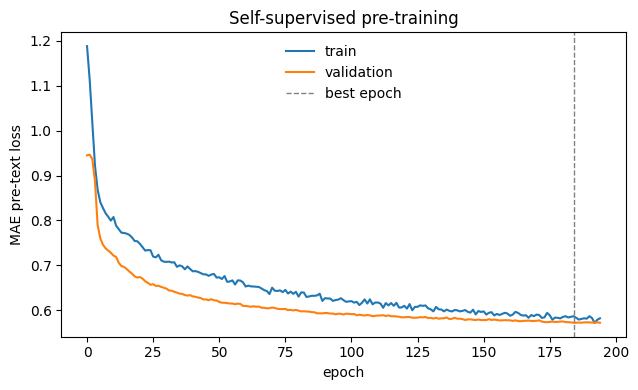

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(hist['epoch'], hist['train_loss'], color='C0', label='train')
ax.plot(hist['epoch'], hist['val_loss'], color='C1', label='validation')
ax.axvline(
    hist['epoch'][best], color='0.5', linestyle='--', linewidth=1, label='best epoch',
)
ax.set_xlabel('epoch')
ax.set_ylabel(f'{encoder.pretext.upper()} pre-text loss')
ax.set_title('Self-supervised pre-training')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 4. Inspect the embeddings

`encoder.transform` returns one embedding per spectrum (shape `(n_samples, feature_dim_)`). Below, the first two principal components of the embeddings next to those of the binned spectra (standardized per bin), coloured by acquisition centre and by Amikacin label. The encoder never saw the labels.

The embedding panels show the 1st to 99th percentile range of each component, widened by 10% on each side, so that a few outlying spectra do not squeeze the cluster; the next cell prints how many fall outside.

In [5]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Z = encoder.transform(demo.X)
views = {
    'Binned spectra': StandardScaler().fit_transform(demo.X),
    'SSL embeddings': Z,
}
projections = {}
for view, data in views.items():
    pca = PCA(n_components=2, random_state=0).fit(data)
    projections[view] = (pca.transform(data), pca.explained_variance_ratio_)

P_ssl = projections['SSL embeddings'][0]
low, high = np.percentile(P_ssl, [1, 99], axis=0)
low, high = low - 0.1 * (high - low), high + 0.1 * (high - low)
outside = ((P_ssl < low) | (P_ssl > high)).any(axis=1)
print(f'SSL embeddings outside the plotted range: {outside.sum()} of {len(P_ssl)}')

SSL embeddings outside the plotted range: 7 of 741


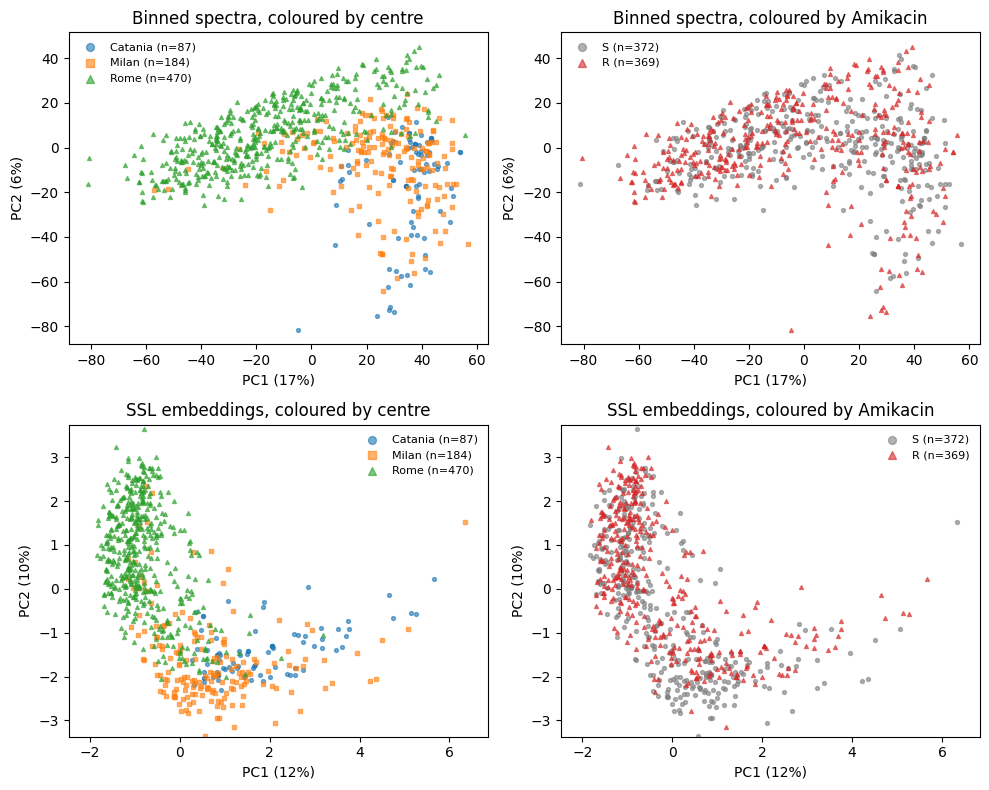

In [6]:
labels = demo.meta['Amikacin'].astype('string')
centres = sorted(demo.batch.unique())
colourings = {  # (values, {level: (colour, marker)}); labels get their own colours
    'centre': (
        demo.batch.astype('string'),
        {c: (f'C{i}', 'os^'[i]) for i, c in enumerate(centres)},
    ),
    'Amikacin': (labels, {'S': ('C7', 'o'), 'R': ('C3', '^')}),
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (view, (P, ev)) in enumerate(projections.items()):
    for col, (name, (values, styles)) in enumerate(colourings.items()):
        ax = axes[row, col]
        for level, (colour, marker) in styles.items():
            mask = (values == level).to_numpy()
            ax.scatter(
                P[mask, 0], P[mask, 1], s=8, alpha=0.6, color=colour, marker=marker,
                label=f'{level} (n={mask.sum()})',
            )
        if view == 'SSL embeddings':
            ax.set_xlim(low[0], high[0])
            ax.set_ylim(low[1], high[1])
        ax.set_xlabel(f'PC1 ({ev[0]:.0%})')
        ax.set_ylabel(f'PC2 ({ev[1]:.0%})')
        ax.set_title(f'{view}, coloured by {name}')
        ax.legend(frameon=False, fontsize=8, markerscale=2)
fig.tight_layout()
plt.show()

## 5. Fine-tune: scratch vs FT vs LP-FT

Three arms, all `MaldiMLPClassifier` with default hyperparameters:

- **scratch**: random initialisation.
- **FT**: `init_from=encoder`, the trunk starts from the pre-trained weights and the whole network is fine-tuned.
- **LP-FT**: as FT, but for the first `freeze_trunk_epochs=10` epochs only the final layer is trained (linear probing; Kumar *et al.*, 2022).

With `init_from`, the classifier also **inherits the encoder's fitted preprocessing** instead of fitting its own on the (small) labeled split.

In [7]:
import pandas as pd
from sklearn.metrics import roc_auc_score

from maldideepkit import MaldiMLPClassifier

ARMS = {
    'scratch': {},
    'FT': {'init_from': encoder},
    'LP-FT': {'init_from': encoder, 'freeze_trunk_epochs': 10},
}

Each arm is trained on 5%, 10%, 25%, 50%, and 100% of the training split (stratified subsamples), with five repeats per fraction (a different subsample and seed each time; at 100% only the seed changes), and scored by test AUROC.

In [8]:
FRACTIONS = [0.05, 0.10, 0.25, 0.50, 1.00]
REPEATS = 5

rows = []
for frac in FRACTIONS:
    for rep in range(REPEATS):
        if frac < 1.0:
            X_sub, _, y_sub, _ = train_test_split(
                X_tr, y_tr, train_size=frac, stratify=y_tr, random_state=rep,
            )
        else:
            X_sub, y_sub = X_tr, y_tr
        for arm, params in ARMS.items():
            clf = MaldiMLPClassifier(random_state=rep, **params).fit(X_sub, y_sub)
            auroc = roc_auc_score(y_te, clf.predict_proba(X_te)[:, 1])
            rows.append({
                'fraction': frac, 'repeat': rep, 'n_train': len(y_sub),
                'arm': arm, 'auroc': auroc,
            })

results = pd.DataFrame(rows)
print(f'{len(results)} fits')

75 fits


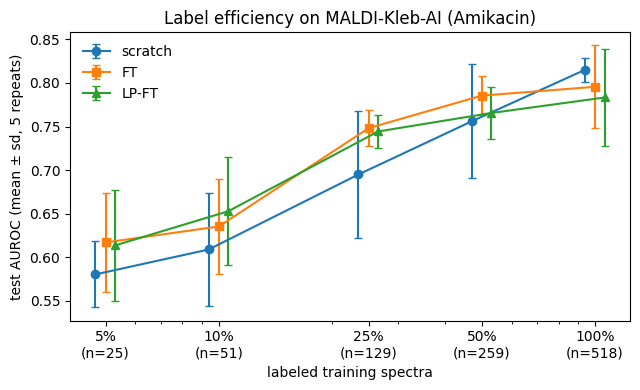

In [9]:
summary = (
    results.groupby(['fraction', 'arm'])['auroc']
    .agg(['mean', 'std'])
    .unstack('arm')
)
n_train = results.groupby('fraction')['n_train'].first()

fig, ax = plt.subplots(figsize=(6.5, 4))
for i, arm in enumerate(ARMS):
    mean, std = summary[('mean', arm)], summary[('std', arm)]
    x = np.asarray(FRACTIONS) * (0.94, 1.0, 1.06)[i]  # dodge the error bars
    ax.errorbar(x, mean, yerr=std, color=f'C{i}', marker='os^'[i], capsize=3, label=arm)
ax.set_xscale('log')
ax.set_xticks(FRACTIONS)
ax.set_xticklabels([f'{f:.0%}\n(n={n_train[f]})' for f in FRACTIONS])
ax.set_xlabel('labeled training spectra')
ax.set_ylabel('test AUROC (mean ± sd, 5 repeats)')
ax.set_title('Label efficiency on MALDI-Kleb-AI (Amikacin)')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [10]:
columns = {}
for arm in ARMS:
    pairs = zip(summary[('mean', arm)], summary[('std', arm)])
    columns[arm] = [f'{m:.3f} ± {s:.3f}' for m, s in pairs]
index = pd.Index([f'{f:.0%}' for f in summary.index], name='labels')
table = pd.DataFrame(columns, index=index)
table

,scratch,FT,LP-FT
labels,,,
5%,0.580 ± 0.038,0.617 ± 0.057,0.614 ± 0.064
10%,0.609 ± 0.064,0.635 ± 0.054,0.653 ± 0.062
25%,0.695 ± 0.073,0.748 ± 0.020,0.744 ± 0.019
50%,0.756 ± 0.066,0.785 ± 0.022,0.766 ± 0.030
100%,0.815 ± 0.014,0.796 ± 0.047,0.783 ± 0.056


## 6. Extending

Nothing above is fixed. These three short examples only show how the pieces fit: they make no claim about which choice works better on this dataset.

The classes live in the notebook, so `save` stores them under `__main__`: a checkpoint reloads in this session, or in another one that defines them again. For checkpoints you keep, put them in an importable module.

### A pre-text task that reads the centre

With `uses_target = True`, the `y` given to `fit` reaches the loss as `batch.target` and `batch.labeled`, without an auxiliary head. Here it is the acquisition centre: the task denoises the spectrum while, through a gradient reversal, the trunk works against an adversary that tries to recover the centre from the embedding.

In [11]:
import copy
import torch
import torch.nn.functional as F
from torch import nn

from maldideepkit.pretraining import Pretext


class _GradReverse(torch.autograd.Function):
    """Identity in the forward pass, negated gradient in the backward pass."""

    @staticmethod
    def forward(ctx, x):
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad):
        return -grad

In [12]:
class CentreInvariantDenoising(Pretext):
    """Denoise the spectrum while an adversary tries to recover the centre."""

    uses_target = True

    def __init__(self, n_centres=3, noise_std=0.1, adversary_weight=0.1):
        self.n_centres = n_centres
        self.noise_std = noise_std
        self.adversary_weight = adversary_weight

    def build_head(self, feature_dim, input_dim):
        return nn.ModuleDict({
            'recon': nn.Linear(feature_dim, input_dim),
            'centre': nn.Linear(feature_dim, self.n_centres),
        })

    def loss(self, model, batch, generator):
        noise = torch.randn(batch.x.shape, generator=generator).to(batch.x.device)
        z = model.forward_features(batch.x + self.noise_std * noise)
        recon = F.mse_loss(model.pretext['recon'](z).float(), batch.x.float())
        logits = model.pretext['centre'](_GradReverse.apply(z)).float()
        adversary = F.cross_entropy(logits[batch.labeled], batch.target[batch.labeled])
        return recon + self.adversary_weight * adversary

In [13]:
centre_encoder = MaldiSpectrumEncoder(
    backbone='mlp', pretext=CentreInvariantDenoising(),
    batch_size=32, epochs=50, random_state=0,
).fit(demo.X, demo.batch)
print(f'centres, in target order: {list(centre_encoder.aux_classes_)}')
print(f'embeddings: {centre_encoder.transform(demo.X).shape}')

centres, in target order: ['Catania', 'Milan', 'Rome']
embeddings: (741, 128)


### A momentum teacher, with the training hooks

A pre-text task has the hooks of a `Callback`: `on_train_start`, `on_epoch_start`, `on_step_end`, `on_epoch_end`, and `on_train_end`. Here a teacher is copied from the model at the start and follows it as a moving average after each optimizer step, as in BYOL. The teacher stays on the pre-text instance, so it reaches neither the checkpoint nor early stopping. This minimal version only shows the hooks and can collapse, so check the spread of its embeddings (printed below).

In [14]:
class MomentumTeacher(Pretext):
    """Match the embedding of a moving-average copy of the model, as in BYOL."""

    def __init__(self, noise_std=0.1, momentum=0.99):
        self.noise_std = noise_std
        self.momentum = momentum

    def build_head(self, feature_dim, input_dim):
        d = feature_dim
        return nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, d))

    def on_train_start(self, model, encoder):
        self.teacher_ = copy.deepcopy(model).eval().requires_grad_(False)

    def on_step_end(self, model, step):
        pairs = zip(self.teacher_.backbone.parameters(), model.backbone.parameters())
        for teacher, student in pairs:
            teacher.data.mul_(self.momentum).add_(student.data, alpha=1 - self.momentum)

    def on_train_end(self, model):
        del self.teacher_

    def _view(self, x, gen):
        return x + self.noise_std * torch.randn(x.shape, generator=gen).to(x.device)

    def loss(self, model, batch, generator):
        online = model.pretext(model.forward_features(self._view(batch.x, generator)))
        with torch.no_grad():
            target = self.teacher_.forward_features(self._view(batch.x, generator))
        return 2 - 2 * F.cosine_similarity(online.float(), target.float(), dim=1).mean()

In [15]:
teacher_encoder = MaldiSpectrumEncoder(
    backbone='mlp', pretext=MomentumTeacher(),
    batch_size=32, epochs=50, random_state=0,
).fit(demo.X)
Z_teacher = teacher_encoder.transform(demo.X)
print(f'epochs run: {len(teacher_encoder.history_["epoch"])}')
print(f'embeddings: {Z_teacher.shape}')
print(f'spread (std per dimension, mean): {Z_teacher.std(axis=0).mean():.4f} '
      f'(MAE encoder: {Z.std(axis=0).mean():.4f})')

epochs run: 50
embeddings: (741, 128)
spread (std per dimension, mean): 0.0012 (MAE encoder: 0.4943)


### A custom backbone, with your own training components

A custom classifier needs a `_build_model` only, and `**kwargs` gives it every parameter of the built-in ones. Its module needs no special interface: the trunk is everything except the `nn.Linear` that produces the output. `register_backbone` gives it a name accepted wherever the package takes an architecture.

`optimizer`, `scheduler`, `loss`, and `callbacks` work the same way on every architecture and on the dual-branch classifier, and all but `loss` on the encoder. `get_embeddings` is the classifier's counterpart of `encoder.transform`.

In [16]:
from functools import partial

from maldideepkit import BaseSpectralClassifier, Callback, register_backbone


class TinyCNN(BaseSpectralClassifier):
    """A small 1-D CNN: one convolution, pooling, and two linear layers."""

    def __init__(self, channels=8, **kwargs):
        super().__init__(**kwargs)
        self.channels = channels

    def _build_model(self):
        return nn.Sequential(
            nn.Unflatten(1, (1, -1)),
            nn.Conv1d(1, self.channels, kernel_size=15, stride=4, padding=7),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(8),
            nn.Flatten(),
            nn.Linear(8 * self.channels, 32),
            nn.ReLU(),
            nn.Linear(32, self.n_classes_),
        )

In [17]:
class ValLoss(Callback):
    """Record the validation loss at the end of each epoch."""

    def __init__(self):
        self.values = []

    def on_epoch_end(self, model, epoch, logs):
        self.values.append(logs['val_loss'])

In [18]:
register_backbone('tiny_cnn', TinyCNN)
tiny_encoder = MaldiSpectrumEncoder(
    backbone='tiny_cnn', batch_size=32, epochs=50, random_state=0,
).fit(demo.X)

val_loss = ValLoss()
tiny = TinyCNN(
    init_from=tiny_encoder,
    freeze_trunk_epochs=5,
    optimizer=partial(torch.optim.SGD, momentum=0.9),
    scheduler=partial(torch.optim.lr_scheduler.StepLR, step_size=10, gamma=0.5),
    loss=nn.CrossEntropyLoss(reduction='none'),
    callbacks=[val_loss],
    epochs=30,
    random_state=0,
).fit(X_tr, y_tr)
print(f'epochs recorded by the callback: {len(val_loss.values)}')
print(f'classifier embeddings: {tiny.get_embeddings(X_te).shape}')

epochs recorded by the callback: 30
classifier embeddings: (223, 32)


## Recap

| Step | API |
|---|---|
| Pre-train on unlabeled spectra | `MaldiSpectrumEncoder(backbone=..., pretext=...).fit(X)` |
| Embeddings | `encoder.transform(X)`, shape `(n_samples, encoder.feature_dim_)` |
| Fine-tune from the trunk | `Classifier(init_from=encoder)` or `init_from='path/to/checkpoint'` |
| Linear probing first (LP-FT) | `Classifier(init_from=..., freeze_trunk_epochs=k)` |
| Reuse later | `encoder.save(path)`, `MaldiSpectrumEncoder.load(path)` |
| Custom pre-text task | subclass `Pretext` (`build_head`, `loss`; optional `uses_target` and training hooks) |
| Custom architecture | subclass `BaseSpectralClassifier` (`_build_model`), `register_backbone(name, cls)` |
| Training components | `optimizer=`, `scheduler=`, `loss=`, and `callbacks=` on every architecture and on the dual-branch classifier, all but `loss=` on the encoder; the self-training classifier takes them through its `base_estimator` |
| Embeddings of a classifier | `clf.get_embeddings(X)` |

A checkpoint path in `init_from` is clone-safe, so it can be searched over in `GridSearchCV` (`{'init_from': [path_a, path_b]}`); a fitted encoder instance is shared by reference across clones. See the [pre-training API page](https://maldideepkit.readthedocs.io/en/latest/api/pretraining.html) for the pre-text tasks, the preprocessing inheritance rules, the custom backbones, and the GPU options.